## Q1

The question is asking to show that $P=U^\top(UU^\top)^{-1}U$ akes a feature vector $x$ and replaces it with its closest approximation inside a smaller subspace. $B$ contains feature vectors of all data points and $K$ is the covariance matrix. Each entry of $K$ is an inner product between two feature vectors, so it measures their similarity. The idea is, instead of keeping every full feature vector in $B$, Gaussian Process selects a smaller set of representative vectors and forms the matrix $U$. For a given original feature vector $x$, we want to find the vector in this smaller subspace that is closest to $x$:

$$
\text{closest approximation of }x = \arg\min_{v\in \operatorname{row}(U)} \|x-v\|^2 
$$

We should prove that the answer is $Px$, where $P$ is the given matrix. 

$U_{r \times d}$ is a matrix containing a small set of representative feature vectors. $r$ is the number of selected representative vectors and $d$ is the number of features in each vector. We also define a weight vector $a$ telling how much of each row of $U$ to use. We can express $\hat{x}=U^\top a$ as a new vector $\hat{x}$ by combining rows of $U$, using weights in $a$. $U^\top a$ represents every possible vector in the subspace spanned by rows of $U$. We have original $x$ and also $\hat{x} = U^\top a$. The goal is to minimize:
$$
|x-U^\top a|^2 
$$

According to linear algebra rule: $\|v\|^2=v^\top v $. We can express the above formula to:

$$
\|x-U^\top a\|^2 = (x-U^\top a)^\top(x-U^\top a) \\ 

= x^\top x - x^\top U^\top a - a^\top Ux + a^\top UU^\top a
$$
The two middle terms are equal scalars ($x^\top U^\top a=a^\top Ux$). Therefore,
$$
\|x-U^\top a\|^2 = x^\top x - 2a^\top Ux + a^\top UU^\top a
$$

OK. Now we should find the minimum of the above formula by finding the best weights $a$. So we take the derivative of it with respect to $a$:

$$
f(a) = x^\top x - 2a^\top Ux + a^\top UU^\top a \\

\frac{\partial f(a)}{\partial a} = -2Ux+2UU^\top a = 0 \rightarrow UU^\top a=Ux
$$

The question assumes that $UU^\top$ is invertible. Therefore, we can multiply both sides by $(UU^\top)^{-1}$

$$
\rightarrow a = (UU^\top)^{-1} Ux
$$

Now that we calculate minimum $a$, we substitute it to $\hat{x}=U^\top a$. It gives us:

$$
\hat{x} = U^\top (UU^\top)^{-1}Ux
$$

If we define $P = U^\top (UU^\top)^{-1}U$, we can express $\hat{x}$ as $\hat{x} = Px$

## Q2

Suppose we have $n$ training examples. Gaussian Process creates a kernel matrix $n \times n$. Each entry $K_{ij}$ measures the similarity between training examples $i$ and $j$. GP regression must compute $(\mathbf K+\sigma^2\mathbf I)\boldsymbol{\alpha} = \mathbf y$ for $\alpha$. This is problematic because matrix $(\mathbf K+\sigma^2\mathbf I)$ is $n \times n$, and solving a general system of this size costs $O(n_3)$.

The question says $K=BB^T$. That means each training example is represented by a row of $B$. The kernel similarity between examples $i$ and $j$ comes from the inner product of their corresponding rows. The initial idea is to approximate every row of $B$ using $m$ representative rows. Consequently, the approximate kernel $\hat{K}$ still has size $n \times n$, but it is constructed from only $m$ fundamental pieces. Therefore, it has rank at most $m$.

The question is asking how can we use that-low-rank structure to calculate $(\bar{\mathbf K}+\sigma^2\mathbf I)^{-1}\mathbf y$ without solving an $n \times n$ system ? Woodbury is the mathematical tool that transforms the problem into an equivalent calculation involving an $m \times m$ system.

We want to calculate $(\bar{\mathbf K}+\sigma^2\mathbf I_n)^{-1}\mathbf y$. Because $\bar{\mathbf K}$ was built using only $m$ representative rows, its rank is at most $m$. Therefore, we can write it as $\bar{\mathbf K}=\mathbf Z\mathbf Z^\top$. Therefore, our main expression becomes:
$$
(\sigma^2\mathbf I_n+\mathbf Z\mathbf Z^\top)^{-1}\mathbf y
$$

Woodbury says: $(\mathbf A+\mathbf U\mathbf C\mathbf V)^{-1} = \mathbf A^{-1} - \mathbf A^{-1}\mathbf U \left(\mathbf C^{-1}+\mathbf V\mathbf A^{-1}\mathbf U \right)^{-1} \mathbf V\mathbf A^{-1}$

We compare our expression with Woodbury formula:
$$
\underbrace{\sigma^2\mathbf I_n}_{\mathbf A} + \underbrace{\mathbf Z}_{\mathbf U} \underbrace{\mathbf I_m}_{\mathbf C} \underbrace{\mathbf Z^\top}_{\mathbf V}
$$

We simply substitute the four matrices and multiply it by $y$:
$$
(\sigma^2\mathbf I_n+\mathbf Z\mathbf Z^\top)^{-1} = \frac{1}{\sigma^2}\mathbf I_n - \frac{1}{\sigma^2}\mathbf I_n\mathbf Z \left(\mathbf I_m+ \mathbf Z^\top \frac{1}{\sigma^2}\mathbf I_n \mathbf Z \right)^{-1} \mathbf Z^\top \frac{1}{\sigma^2}\mathbf I_n
$$
The identity matrices disappear when multiplied:
$$
(\sigma^2\mathbf I_n+\mathbf Z\mathbf Z^\top)^{-1} = \frac{1}{\sigma^2}\mathbf I_n - \frac{1}{\sigma^4} \mathbf Z \left(\mathbf I_m+\frac{1}{\sigma^2}\mathbf Z^\top\mathbf Z \right)^{-1} \mathbf Z^\top
$$
Finally, we multiply each side by $y$:
$$
(\bar{\mathbf K}+\sigma^2\mathbf I_n)^{-1}\mathbf y = \frac{1}{\sigma^2}\mathbf y - \frac{1}{\sigma^4} \mathbf Z \left(\mathbf I_m+ \frac{1}{\sigma^2}\mathbf Z^\top\mathbf Z \right)^{-1} \mathbf Z^\top\mathbf y
$$

Now in this expression, the only part which is nontrivial is $\left(\mathbf I_m+ \frac{1}{\sigma^2}\mathbf Z^\top\mathbf Z \right)^{-1}$ because $\mathbf Z^\top\mathbf Z: \quad (m\times n)(n\times m) = m\times m$

## Q4

In [4]:
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.svm import SVR
import numpy as np

# loading concrete data

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/concrete/compressive/Concrete_Data.xls"
data = pd.read_excel(url)
X = data.iloc[:, :-1].values
y = data.iloc[:, -1].values

# scaling: standard scaler removes mean from feature components and scales them to unit variance
# this is to ensure training stability, no feature will dominate the kernel computation
scaler_X = StandardScaler()
scaler_y = StandardScaler()
X = scaler_X.fit_transform(X)
y = scaler_y.fit_transform(y.reshape(-1, 1)).ravel()

# splitting data into train and test -- note that we will practice using PyTorch for training so all vectors/matrices will be on torch
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32)
X_test_t = torch.tensor(X_test, dtype=torch.float32)

# we will now implement the RBF kernel discussed in class
def ard_rbf_kernel(X1, X2, lengthscales, variance):
    # Divide each feature by its own lengthscale.
    X1_scaled = X1 / lengthscales
    X2_scaled = X2 / lengthscales

    # Shape: (number of X1 points, number of X2 points)
    squared_distances = torch.cdist(X1_scaled, X2_scaled, p=2).pow(2)

    # The assignment formula uses sigma^2.
    return variance.pow(2) * torch.exp(-0.5 * squared_distances)

# we will now implement the Gaussian process model
class GPModelARD(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.log_lengthscales = nn.Parameter(torch.zeros(n_features))  # one per feature, stored in log form
        self.log_var = nn.Parameter(torch.tensor(0.0))                 # kernel variance, stored in log form
        self.log_noise = nn.Parameter(torch.tensor(-1.0))              # noise variance, stored in log form

    def kernel(self, X1, X2):  # this is the kernel wrapper to bridge between the log form parameterization and the original kernel implementation
        lengthscales = torch.exp(self.log_lengthscales)
        variance = torch.exp(self.log_var)
        return ard_rbf_kernel(X1, X2, lengthscales, variance)

    def nll(self, X, y):  # compute -log p(y | X) according to the GP model (can ignore constant that does not depend on any parameters)
        n = X.shape[0]
        K = self.kernel(X, X) + torch.exp(self.log_noise) * torch.eye(n)
        L = torch.linalg.cholesky(K)
        alpha = torch.cholesky_solve(y.view(-1,1), L)
        nll = 0.5 * y.view(1,-1) @ alpha
        nll += torch.sum(torch.log(torch.diag(L)))
        nll += 0.5 * n * torch.log(torch.tensor(2.0 * torch.pi))
        return nll.squeeze()

    def predict(self, X_train, y_train, X_test):
        n_train = X_train.shape[0]
        eye = torch.eye(n_train, dtype=X_train.dtype, device=X_train.device,)

        noise_variance = torch.exp(self.log_noise)

        # K(X_train, X_train) + noise variance
        K_train = self.kernel(X_train, X_train) + (noise_variance + 1e-6) * eye
        L = torch.linalg.cholesky(K_train)

        K_train_test = self.kernel(X_train, X_test)
        K_test_test = self.kernel(X_test, X_test)

        alpha = torch.cholesky_solve(y_train.view(-1, 1), L)

        # Posterior mean
        mean = K_train_test.T @ alpha

        # Posterior covariance diagonal
        v = torch.linalg.solve_triangular(L, K_train_test, upper=False)
        covariance = K_test_test - v.T @ v
        variance = torch.diagonal(covariance).clamp_min(0.0)

        return mean.squeeze(), variance

# ======================
# Train GP
# ======================
model = GPModelARD(n_features=X_train_t.shape[1])
optimizer = optim.Adam(model.parameters(), lr=0.05)

model.train()

for step in range(500):
    optimizer.zero_grad()

    loss = model.nll(X_train_t, y_train_t)

    loss.backward()
    optimizer.step()

    if step % 100 == 0:
        print(f"Step {step}, NLL: {loss.item():.3f}")

# GP Predictions
model.eval()
mean_pred, var_pred = model.predict(X_train_t, y_train_t, X_test_t,)
y_pred_gp = scaler_y.inverse_transform(mean_pred.detach().numpy().reshape(-1,1)).ravel()
y_true = scaler_y.inverse_transform(y_test.reshape(-1,1)).ravel()

rmse_gp = np.sqrt(mean_squared_error(y_true, y_pred_gp))

print("\n===== GP Learned Lengthscales (per feature) =====")
print(torch.exp(model.log_lengthscales).data.numpy())

# setting up some baseline for comparison. this part requires you to read the documentation of scikit-learn and understand how to setup the appropriate ML module

dt = DecisionTreeRegressor(random_state=42)
dt.fit(X_train, y_train)
y_pred_dt = scaler_y.inverse_transform(dt.predict(X_test).reshape(-1,1)).ravel()
rmse_dt = np.sqrt(mean_squared_error(y_true, y_pred_dt))

lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = scaler_y.inverse_transform(lr.predict(X_test).reshape(-1,1)).ravel()
rmse_lr = np.sqrt(mean_squared_error(y_true, y_pred_lr))

mlp = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=2000, early_stopping=True, random_state=42,)
mlp.fit(X_train, y_train)
y_pred_mlp = scaler_y.inverse_transform(mlp.predict(X_test).reshape(-1,1)).ravel()
rmse_mlp = np.sqrt(mean_squared_error(y_true, y_pred_mlp))

# baseline: Support Vector Regression using sklearn SVR and compute RMSE
svr = SVR(kernel='rbf', C = 10, epsilon = 0.1)
svr.fit(X_train, y_train)
y_pred_svr = scaler_y.inverse_transform(svr.predict(X_test).reshape(-1,1)).ravel()
rmse_svr = np.sqrt(mean_squared_error(y_true, y_pred_svr))

# print result

print("\n===== Model Comparison on Concrete Dataset (RMSE) =====")
print(f"GP (RBF)    RMSE: {rmse_gp:.3f}")
print(f"Decision Tree   RMSE: {rmse_dt:.3f}")
print(f"Linear Regress. RMSE: {rmse_lr:.3f}")
print(f"Neural Network  RMSE: {rmse_mlp:.3f}")
print(f"SVR (RBF)       RMSE: {rmse_svr:.3f}")


Step 0, NLL: 751.365
Step 100, NLL: 301.606
Step 200, NLL: 301.591
Step 300, NLL: 301.590
Step 400, NLL: 301.592

===== GP Learned Lengthscales (per feature) =====
[2.2348175 2.670436  2.6744847 3.1567912 3.3576016 2.5205004 3.1555965
 0.918551 ]

===== Model Comparison on Concrete Dataset (RMSE) =====
GP (RBF)    RMSE: 5.577
Decision Tree   RMSE: 6.796
Linear Regress. RMSE: 9.797
Neural Network  RMSE: 5.608
SVR (RBF)       RMSE: 5.788


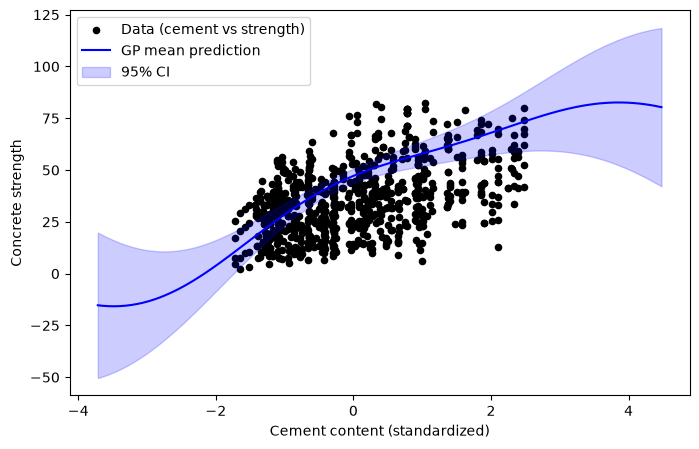

In [5]:
import matplotlib.pyplot as plt # import plotting library

# we will visualize the prediction and prediction uncertainty of Gaussian process with respect to one particular feature (e.g., cement = feature 0)
# to ablate the predictive behavior with respect to this feature, we will set the rest of the feature as by their empirical mean, i.e., f[i] = mean(f[i])
# ======================
feature_idx = 0   # this is the index of the first feature
n_points = 200

# Use the mean of TRAINING inputs (already scaled)
X_mean = X_train.mean(axis=0)
X_plot = np.tile(X_mean, (n_points, 1))

# Sweep this feature across a wider range. We will plot the GP predictive function across these points
x_range = np.linspace(X_train[:, feature_idx].min()-2,
                      X_train[:, feature_idx].max()+2,
                      n_points)

X_plot[:, feature_idx] = x_range
X_plot_t = torch.tensor(X_plot, dtype=torch.float32)

# GP predictions: Make prediction at X_plot_t given X_train_t and y_train_t with the learned Gaussian process
#                 We need both the prediction y_pred and its prediction standard deviation y_std

mean_pred, var_pred = model.predict(X_train_t, y_train_t, X_plot_t)
y_pred = scaler_y.inverse_transform(mean_pred.detach().numpy().reshape(-1,1)).ravel()
y_std = np.sqrt(var_pred.detach().numpy() * scaler_y.var_[0])

# Training data projected onto chosen feature (cement) -- we will visualize the prediction function within the scatter plot of training data points
train_feature = X_train[:, feature_idx]
train_target = scaler_y.inverse_transform(y_train.reshape(-1,1)).ravel()

# ======================
# Plot
# ======================
plt.figure(figsize=(8,5))
plt.scatter(train_feature, train_target, c='k', s=20, label="Data (cement vs strength)")
plt.plot(x_range, y_pred, 'b-', label="GP mean prediction")
plt.fill_between(x_range, y_pred - 2*y_std, y_pred + 2*y_std,
                 color='blue', alpha=0.2, label="95% CI")
plt.xlabel("Cement content (standardized)")
plt.ylabel("Concrete strength")
plt.legend()
plt.show()


The black dots are actual training examples. They have large vertical spread because their other features are not actually fixed at their means. The blue line is the GP’s mean prediction. Because an RBF kernel is used, it should be smooth. The shaded band is $\text{prediction mean} \pm 2\text{ prediction standard deviations}$. Under the GP Gaussian assumption, this is approximately a 95% uncertainty interval. The band should generally be narrower where the test point is similar to many training examples, and wider in poorly supported or extrapolation regions. Prediction uncertainty is lower in regions supported by similar training data.